# Phase 2 - Model Building, Tuning, Comparison and Analysis
**Project:** Eye-state (open / closed) detection for drowsiness monitoring.
**Target:** `closed` (1 = closed, 0 = open). Missing a closed eye is the costly error, so we focus on **recall and F1 of the closed class** plus AUC.

All models are trained **only on the cleaned data from Phase 1** (`eye_dataset_64.npz`, `splits.csv`, `metadata_clean.csv`, `normalization_stats.json`), using the same **subject-wise** train / val / test split, so no person appears in two splits.

| Step | What we do |
|---|---|
| 1 | Load cleaned data, check alignment with metadata, look at class balance |
| 2 | **Classical ML**: HOG features + Logistic Regression / SVM / Random Forest, tuned with **GroupKFold cross-validation** (grouped by subject) |
| 3 | **Deep learning**: (a) Phase 1 baseline CNN, (b) CNN tuned with a hyper-parameter search, (c) small ResNet, (d) MobileNetV2 transfer learning |
| 4 | Threshold chosen on the **validation** set for every model; test set used once |
| 5 | Comparison table, ROC / PR curves, confusion matrices, training curves |
| 6 | Best-model analysis: per-condition and per-subject results, threshold trade-off, error gallery, occlusion sensitivity |
| 7 | Save the best model + config for the website, conclusion |

In [7]:
import shutil, os
SRC = '/kaggle/input/datasets/hassanali5744/eyedata'
DST = '/kaggle/working/data/processed'
os.makedirs(DST, exist_ok=True)
for f in ['eye_dataset_64.npz', 'splits.csv', 'metadata_clean.csv', 'normalization_stats.json']:
    shutil.copy(f'{SRC}/{f}', DST)
print(os.listdir(DST))

['metadata_clean.csv', 'eye_dataset_64.npz', 'normalization_stats.json', 'splits.csv']


In [6]:
for root, dirs, files in os.walk('/kaggle/input'):
    print("Folder:", root)
    print("Files:", files)

Folder: /kaggle/input
Files: []
Folder: /kaggle/input/datasets
Files: []
Folder: /kaggle/input/datasets/hassanali5744
Files: []
Folder: /kaggle/input/datasets/hassanali5744/eyedata
Files: ['eye_dataset_64.npz', 'metadata_clean.csv', 'normalization_stats.json', 'splits.csv']


In [11]:
import os, json, random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from joblib import Parallel, delayed, dump
from skimage.feature import hog
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve)
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')
PROC_DIR = '/kaggle/working/data/processed'
IMG_DIR = '/kaggle/working/images'
MODEL_DIR = '/kaggle/working/models'

for d in (IMG_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)
for d in (IMG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)

QUICK = False                      # True = tiny run to test the notebook end to end
EPOCHS, BATCH = (2, 64) if QUICK else (30, 64)
TUNE_EPOCHS   = 1 if QUICK else 8   # epochs per configuration in the CNN hyper-parameter search
N_TUNE, N_CLASSICAL = (2000, 4000) if QUICK else (12000, 25000)   # subsample sizes for classical models
def savefig(name): plt.savefig(os.path.join(IMG_DIR, name), dpi=150, bbox_inches='tight')
print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))

TensorFlow 2.21.0 | GPU: True


## 1. Load the cleaned data
Images are `uint8` 64x64 grayscale; we scale to [0, 1] as in notebook 03. The metadata of every split is aligned with the image arrays (checked with assertions) so we can group by **subject** for cross-validation and evaluate by **condition** later.

In [12]:
d = np.load(f'{PROC_DIR}/eye_dataset_64.npz')
def prep(x): 
    x = x.astype('float32') / 255
    return x[..., None] if x.ndim == 3 else x
Xtr, ytr = prep(d['X_train']), d['y_train'].astype('int32')
Xva, yva = prep(d['X_val']),   d['y_val'].astype('int32')
Xte, yte = prep(d['X_test']),  d['y_test'].astype('int32')
stats = json.load(open(f'{PROC_DIR}/normalization_stats.json'))
class_weights = {int(k): v for k, v in stats['class_weights'].items()}

splits = pd.read_csv(f'{PROC_DIR}/splits.csv')
meta = pd.read_csv(f'{PROC_DIR}/metadata_clean.csv')[['rel_path', 'gender', 'glasses', 'reflections', 'lighting', 'sensor']]
def split_meta(name, y):
    m = splits[splits.split == name].merge(meta, on='rel_path', how='left').reset_index(drop=True)
    assert len(m) == len(y) and (m.closed.values == y).all(), f'{name} metadata is not aligned with the arrays'
    return m
tr_meta, va_meta, te_meta = split_meta('train', ytr), split_meta('val', yva), split_meta('test', yte)

print('train', Xtr.shape, '| val', Xva.shape, '| test', Xte.shape)
print('class weights:', {k: round(v, 3) for k, v in class_weights.items()})
print('subjects  train/val/test:', tr_meta.subject.nunique(), va_meta.subject.nunique(), te_meta.subject.nunique())
assert not (set(tr_meta.subject) & set(te_meta.subject)) and not (set(tr_meta.subject) & set(va_meta.subject)), 'subject leakage!'
print('No subject appears in more than one split: OK')

train (55267, 64, 64, 1) | val (23494, 64, 64, 1) | test (6066, 64, 64, 1)
class weights: {0: 0.966, 1: 1.036}
subjects  train/val/test: 25 6 6
No subject appears in more than one split: OK


        train    val   test
open    0.517  0.489  0.469
closed  0.483  0.511  0.531


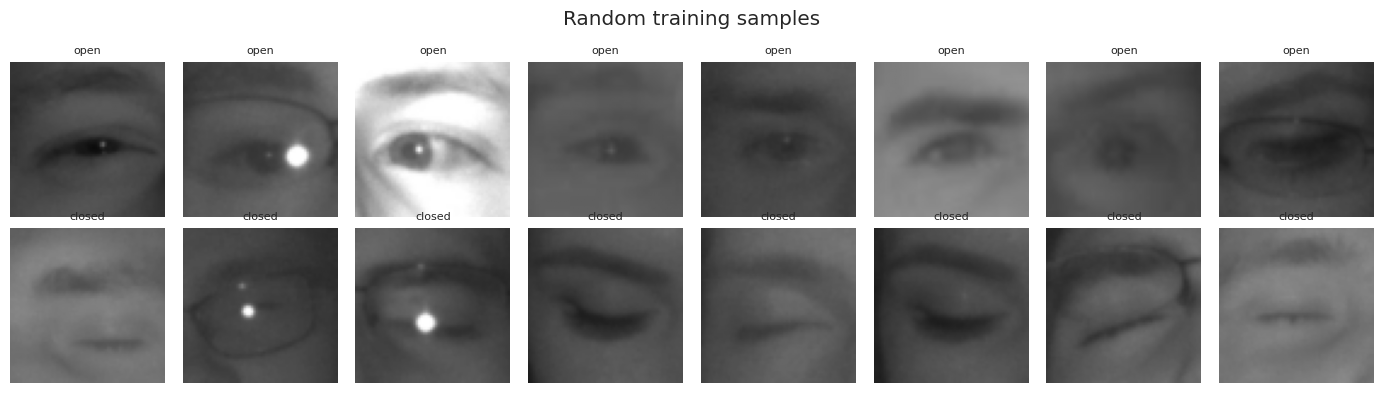

In [13]:
bal = pd.DataFrame({'train': pd.Series(ytr).value_counts(normalize=True), 'val': pd.Series(yva).value_counts(normalize=True),
                    'test': pd.Series(yte).value_counts(normalize=True)}).rename(index={0: 'open', 1: 'closed'}).round(3)
print(bal)
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
rng = np.random.RandomState(SEED)
for j in range(8):
    for i, c in enumerate([0, 1]):
        k = rng.choice(np.where(ytr == c)[0]); ax[i, j].imshow(Xtr[k, ..., 0], cmap='gray', vmin=0, vmax=1); ax[i, j].axis('off')
        ax[i, j].set_title('closed' if c else 'open', fontsize=8)
plt.suptitle('Random training samples'); plt.tight_layout(); savefig('p2_01_samples.png'); plt.show()

## 2. Shared evaluation tools
Every model - classical or deep - goes through **the same function**:
1. predict probabilities for validation and test images,
2. pick the decision threshold that maximises **F1 on the validation set**,
3. report test metrics at that threshold (the test set is never used to choose anything),
4. measure end-to-end inference time per image.

Model selection later uses **validation** F1, not test numbers.

In [19]:
results, PRED, HIST, MODELS = [], {}, {}, {}

def best_threshold(y, p):
    ts = np.arange(0.05, 0.96, 0.01)
    return float(ts[int(np.argmax([f1_score(y, (p >= t).astype(int), zero_division=0) for t in ts]))])

def latency_ms(fn, X, n=500):
    fn(X[:8]); t = time.time(); fn(X[:n]); return (time.time() - t) / min(n, len(X)) * 1000

def evaluate(name, family, pva, pte, train_s, lat, params=''):
    thr = best_threshold(yva, pva); yhat = (pte >= thr).astype(int)
    row = dict(model=name, family=family, threshold=thr,
               val_f1=f1_score(yva, (pva >= thr).astype(int), zero_division=0), val_auc=roc_auc_score(yva, pva),
               accuracy=accuracy_score(yte, yhat), precision_closed=precision_score(yte, yhat, zero_division=0),
               recall_closed=recall_score(yte, yhat, zero_division=0), f1_closed=f1_score(yte, yhat, zero_division=0),
               auc=roc_auc_score(yte, pte), train_time_s=train_s, ms_per_image=lat, params=params)
    results.append(row); PRED[name] = {'val': pva, 'test': pte, 'thr': thr}
    print(f"{name:<22} thr={thr:.2f} | test acc {row['accuracy']:.4f} | recall(closed) {row['recall_closed']:.4f} | "
          f"F1 {row['f1_closed']:.4f} | AUC {row['auc']:.4f} | {lat:.2f} ms/img")

## 3. Classical machine learning on HOG features
Raw pixels are a weak input for classical models, so we describe each eye with **HOG (histogram of oriented gradients)** features, which capture the eyelid / iris edges and are fairly robust to brightness changes. Three models are compared:

* **Logistic Regression** - linear baseline
* **SVM (RBF)** with PCA - strong non-linear classical model
* **Random Forest** - tree ensemble

Hyper-parameters are chosen with **3-fold `GroupKFold` cross-validation grouped by subject** (a person never sits in both the training and validation fold of the CV). To keep run time reasonable, CV runs on a stratified subsample (`N_TUNE`) and the best settings are refitted on a larger subsample (`N_CLASSICAL`). The deep models below use the full training set.

In [20]:
def _hog(img): return hog(img[..., 0], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), feature_vector=True)
def hog_feats(X): return np.asarray(Parallel(n_jobs=-1, batch_size=256)(delayed(_hog)(x) for x in X), dtype='float32')

def subsample(n):
    if n >= len(ytr): return np.arange(len(ytr))
    idx = []
    for c in (0, 1):
        ci = np.where(ytr == c)[0]; idx.append(rng.choice(ci, int(n * (ytr == c).mean()), replace=False))
    return np.sort(np.concatenate(idx))

t = time.time()
i_tune, i_fit = subsample(N_TUNE), subsample(N_CLASSICAL)
H_tune, H_fit = hog_feats(Xtr[i_tune]), hog_feats(Xtr[i_fit])
H_va, H_te = hog_feats(Xva), hog_feats(Xte)
print(f'HOG feature size: {H_fit.shape[1]} | tune {len(i_tune)} | fit {len(i_fit)} | {time.time()-t:.0f}s')

HOG feature size: 1764 | tune 11999 | fit 24999 | 50s


In [21]:
grids = {
 'LogReg (HOG)': (Pipeline([('sc', StandardScaler()), ('clf', LogisticRegression(class_weight='balanced', max_iter=500))]),
                  {'clf__C': [0.01, 0.1, 1]}),
 'SVM-RBF (HOG)': (Pipeline([('sc', StandardScaler()), ('pca', PCA(100, random_state=SEED)), ('clf', SVC(kernel='rbf', class_weight='balanced'))]),
                   {'clf__C': [1, 10], 'clf__gamma': ['scale', 0.003]}),
 'RandomForest (HOG)': (RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=SEED),
                        {'n_estimators': [200], 'max_depth': [None, 25], 'max_features': ['sqrt']}),
}
def score_fn(est):
    if hasattr(est, 'predict_proba'): return lambda H: est.predict_proba(H)[:, 1]
    return lambda H: 1 / (1 + np.exp(-est.decision_function(H)))     # SVM margin -> (0,1)

cv = GroupKFold(n_splits=3)
cv_rows = []
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='roc_auc', n_jobs=-1, refit=False)
    gs.fit(H_tune, ytr[i_tune], groups=tr_meta.subject.values[i_tune])
    r = pd.DataFrame(gs.cv_results_)
    cv_rows.append(r.assign(model=name)[['model', 'params', 'mean_test_score', 'std_test_score', 'rank_test_score']])
    best = clone(pipe).set_params(**gs.best_params_)
    t = time.time(); best.fit(H_fit, ytr[i_fit]); tt = time.time() - t
    sc = score_fn(best)
    lat = latency_ms(lambda X: sc(hog_feats(X)), Xte)
    evaluate(name, 'Classical ML', sc(H_va), sc(H_te), tt, lat, params=str(gs.best_params_))
    MODELS[name] = best

cv_table = pd.concat(cv_rows).sort_values(['model', 'rank_test_score'])
cv_table.to_csv(f'{PROC_DIR}/phase2_classical_cv.csv', index=False)
cv_table.round(4)

LogReg (HOG)           thr=0.66 | test acc 0.8976 | recall(closed) 0.8749 | F1 0.9008 | AUC 0.9589 | 0.91 ms/img
SVM-RBF (HOG)          thr=0.53 | test acc 0.9153 | recall(closed) 0.9001 | F1 0.9186 | AUC 0.9729 | 1.44 ms/img
RandomForest (HOG)     thr=0.50 | test acc 0.9034 | recall(closed) 0.9150 | F1 0.9096 | AUC 0.9689 | 0.93 ms/img


,model,params,mean_test_score,std_test_score,rank_test_score
0,LogReg (HOG),{'clf__C': 0.01},0.9299,0.0068,1
1,LogReg (HOG),{'clf__C': 0.1},0.9227,0.0045,2
2,LogReg (HOG),{'clf__C': 1},0.9179,0.0048,3
1,RandomForest (HOG),"{'max_depth': 25, 'max_features': 'sqrt', 'n_e...",0.9408,0.0087,1
0,RandomForest (HOG),"{'max_depth': None, 'max_features': 'sqrt', 'n...",0.9403,0.0095,2
2,SVM-RBF (HOG),"{'clf__C': 10, 'clf__gamma': 'scale'}",0.9571,0.0053,1
0,SVM-RBF (HOG),"{'clf__C': 1, 'clf__gamma': 'scale'}",0.9538,0.0019,2
3,SVM-RBF (HOG),"{'clf__C': 10, 'clf__gamma': 0.003}",0.9496,0.0140,3
1,SVM-RBF (HOG),"{'clf__C': 1, 'clf__gamma': 0.003}",0.9479,0.0143,4


**Reading the CV table:** `mean_test_score` is the cross-validated AUC on *unseen subjects*. A small `std_test_score` means the choice of hyper-parameters is stable across people.

## 4. Deep learning models
All networks use the same light **augmentation** (flip, small shift / zoom, brightness, contrast - active only during training), **class weights** from the training set, **Adam**, early stopping on validation AUC and learning-rate reduction on plateau.

In [26]:
L = tf.keras.layers
def aug_block():
    return tf.keras.Sequential([L.RandomFlip('horizontal'), L.RandomTranslation(0.08, 0.08, fill_mode='nearest'),
                                L.RandomZoom(0.10, fill_mode='nearest'), L.RandomBrightness(0.25, value_range=(0, 1)),
                                L.RandomContrast(0.25)], name='augmentation')

def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall'),
                       tf.keras.metrics.AUC(name='auc')])
    return m

def callbacks(patience=5):
    return [tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=patience, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)]

def fit(m, epochs, verbose=2):
    t = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=BATCH,
              class_weight=class_weights, callbacks=callbacks(), verbose=verbose)
    return pd.DataFrame(h.history), time.time() - t

def register_keras(name, m, hist, train_s, params=''):
    pva = m.predict(Xva, batch_size=256, verbose=0).ravel(); pte = m.predict(Xte, batch_size=256, verbose=0).ravel()
    lat = latency_ms(lambda X: m.predict(X, batch_size=256, verbose=0), Xte)
    evaluate(name, 'Deep learning', pva, pte, train_s, lat, params=params)
    MODELS[name] = m; HIST[name] = hist
    m.save(f"{MODEL_DIR}/p2_{name.replace(' ', '_').replace('(', '').replace(')', '')}.keras")

### 4.1 Baseline CNN (Phase 1 architecture)
Four convolution blocks + batch-norm + global average pooling + dropout - the model from the Phase 1 bridge notebook. It is our reference point.

In [27]:
def build_cnn(base=32, dropout=0.4, dense=128):
    f = [base, base * 2, base * 4, base * 4]
    inp = L.Input(shape=(64, 64, 1)); x = aug_block()(inp)
    for i, k in enumerate(f):
        x = L.Conv2D(k, 3, padding='same', activation='relu')(x); x = L.BatchNormalization()(x)
        x = L.MaxPooling2D()(x) if i < 3 else L.GlobalAveragePooling2D()(x)
    x = L.Dropout(dropout)(x); x = L.Dense(dense, activation='relu')(x); x = L.Dropout(dropout - 0.1)(x)
    return tf.keras.Model(inp, L.Dense(1, activation='sigmoid')(x))

m = compile_model(build_cnn(32, 0.4), 3e-4); m.summary()
h, tt = fit(m, EPOCHS)
register_keras('CNN baseline', m, h, tt, params='base=32, dropout=0.4, lr=3e-4')

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,305 (1009.00 KB)

 Trainable params: 257,601 (1006.25 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/30
864/864 - 35s - 41ms/step - accuracy: 0.8789 - auc: 0.9574 - loss: 0.2649 - precision: 0.8548 - recall: 0.9023 - val_accuracy: 0.9668 - val_auc: 0.9943 - val_loss: 0.0971 - val_precision: 0.9494 - val_recall: 0.9876 - learning_rate: 3.0000e-04
Epoch 2/30
864/864 - 24s - 27ms/step - accuracy: 0.9691 - auc: 0.9953 - loss: 0.0831 - precision: 0.9653 - recall: 0.9710 - val_accuracy: 0.9461 - val_auc: 0.9935 - val_loss: 0.1417 - val_precision: 0.9098 - val_recall: 0.9930 - learning_rate: 3.0000e-04
Epoch 3/30
864/864 - 23s - 27ms/step - accuracy: 0.9772 - auc: 0.9969 - loss: 0.0639 - precision: 0.9756 - recall: 0.9771 - val_accuracy: 0.9732 - val_auc: 0.9945 - val_loss: 0.0798 - val_precision: 0.9634 - val_recall: 0.9849 - learning_rate: 3.0000e-04
Epoch 4/30
864/864 - 23s - 27ms/step - accuracy: 0.9800 - auc: 0.9976 - loss: 0.0556 - precision: 0.9789 - recall: 0.9796 - val_accuracy: 0.9741 - val_auc: 0.9960 - val_loss: 0.0718 - val_precision: 0.9640 - val_recall: 0.9862 - learni

### 4.2 Hyper-parameter search for the CNN
A small grid over **learning rate x dropout x network width**. Each configuration is trained for `TUNE_EPOCHS` epochs and ranked by **validation AUC** (the test set is not involved). The best configuration is then retrained for the full number of epochs.

In [28]:
import itertools
grid = list(itertools.product([1e-3, 3e-4], [0.3, 0.5], [16, 32]))
if QUICK: grid = grid[:2]
rows = []
for lr, dr, base in grid:
    tf.keras.utils.set_random_seed(SEED)
    mm = compile_model(build_cnn(base, dr), lr)
    t = time.time()
    hh = mm.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=TUNE_EPOCHS, batch_size=BATCH, class_weight=class_weights, verbose=0)
    va = pd.DataFrame(hh.history)
    rows.append({'lr': lr, 'dropout': dr, 'width': base, 'val_auc': va.val_auc.max(), 'val_loss': va.val_loss.min(), 'time_s': time.time() - t})
    print(rows[-1])
tune = pd.DataFrame(rows).sort_values('val_auc', ascending=False).reset_index(drop=True)
tune.to_csv(f'{PROC_DIR}/phase2_cnn_tuning.csv', index=False)
tune.round(4)

{'lr': 0.001, 'dropout': 0.3, 'width': 16, 'val_auc': 0.991675853729248, 'val_loss': 0.1166510358452797, 'time_s': 138.24795699119568}
{'lr': 0.001, 'dropout': 0.3, 'width': 32, 'val_auc': 0.9943262934684753, 'val_loss': 0.09092508256435394, 'time_s': 197.55023169517517}
{'lr': 0.001, 'dropout': 0.5, 'width': 16, 'val_auc': 0.9957047700881958, 'val_loss': 0.07826051861047745, 'time_s': 134.45648527145386}
{'lr': 0.001, 'dropout': 0.5, 'width': 32, 'val_auc': 0.9954277873039246, 'val_loss': 0.08750909566879272, 'time_s': 194.99379014968872}
{'lr': 0.0003, 'dropout': 0.3, 'width': 16, 'val_auc': 0.9949138760566711, 'val_loss': 0.0915181115269661, 'time_s': 138.12327790260315}
{'lr': 0.0003, 'dropout': 0.3, 'width': 32, 'val_auc': 0.9960440993309021, 'val_loss': 0.07328686863183975, 'time_s': 196.7597794532776}
{'lr': 0.0003, 'dropout': 0.5, 'width': 16, 'val_auc': 0.9964016675949097, 'val_loss': 0.06725320219993591, 'time_s': 135.35380148887634}
{'lr': 0.0003, 'dropout': 0.5, 'width': 32

,lr,dropout,width,val_auc,val_loss,time_s
0,0.0003,0.5,16,0.9964,0.0673,135.3538
1,0.0003,0.3,32,0.9960,0.0733,196.7598
2,0.0003,0.5,32,0.9958,0.0891,195.1756
3,0.0010,0.5,16,0.9957,0.0783,134.4565
4,0.0010,0.5,32,0.9954,0.0875,194.9938
5,0.0003,0.3,16,0.9949,0.0915,138.1233
6,0.0010,0.3,32,0.9943,0.0909,197.5502
7,0.0010,0.3,16,0.9917,0.1167,138.2480


In [29]:
b = tune.iloc[0]; print('Best config:', b.to_dict())
tf.keras.utils.set_random_seed(SEED)
m = compile_model(build_cnn(int(b.width), float(b.dropout)), float(b.lr))
h, tt = fit(m, EPOCHS)
register_keras('CNN tuned', m, h, tt, params=f'base={int(b.width)}, dropout={b.dropout}, lr={b.lr}')

Best config: {'lr': 0.0003, 'dropout': 0.5, 'width': 16.0, 'val_auc': 0.9964016675949097, 'val_loss': 0.06725320219993591, 'time_s': 135.35380148887634}
Epoch 1/30
864/864 - 20s - 23ms/step - accuracy: 0.8217 - auc: 0.9140 - loss: 0.3674 - precision: 0.7886 - recall: 0.8614 - val_accuracy: 0.9215 - val_auc: 0.9863 - val_loss: 0.1867 - val_precision: 0.9658 - val_recall: 0.8776 - learning_rate: 3.0000e-04
Epoch 2/30
864/864 - 15s - 18ms/step - accuracy: 0.9537 - auc: 0.9902 - loss: 0.1232 - precision: 0.9461 - recall: 0.9587 - val_accuracy: 0.9678 - val_auc: 0.9948 - val_loss: 0.0898 - val_precision: 0.9513 - val_recall: 0.9876 - learning_rate: 3.0000e-04
Epoch 3/30
864/864 - 15s - 18ms/step - accuracy: 0.9658 - auc: 0.9939 - loss: 0.0943 - precision: 0.9614 - recall: 0.9680 - val_accuracy: 0.9638 - val_auc: 0.9945 - val_loss: 0.0901 - val_precision: 0.9622 - val_recall: 0.9671 - learning_rate: 3.0000e-04
Epoch 4/30
864/864 - 15s - 17ms/step - accuracy: 0.9723 - auc: 0.9954 - loss: 0.07

### 4.3 Small ResNet
Residual (skip) connections make deeper networks easier to train and usually help on harder cases such as glasses and reflections.

In [30]:
def res_block(x, f, stride=1):
    s = x
    y = L.Conv2D(f, 3, strides=stride, padding='same', use_bias=False)(x); y = L.BatchNormalization()(y); y = L.Activation('relu')(y)
    y = L.Conv2D(f, 3, padding='same', use_bias=False)(y); y = L.BatchNormalization()(y)
    if stride != 1 or s.shape[-1] != f: s = L.BatchNormalization()(L.Conv2D(f, 1, strides=stride, use_bias=False)(s))
    return L.Activation('relu')(L.Add()([y, s]))

def build_resnet(dropout=0.4):
    inp = L.Input(shape=(64, 64, 1)); x = aug_block()(inp)
    x = L.Conv2D(32, 3, padding='same', use_bias=False)(x); x = L.BatchNormalization()(x); x = L.Activation('relu')(x)
    for f, s in [(32, 1), (64, 2), (128, 2), (256, 2)]: x = res_block(x, f, s)
    x = L.GlobalAveragePooling2D()(x); x = L.Dropout(dropout)(x)
    return tf.keras.Model(inp, L.Dense(1, activation='sigmoid')(x))

tf.keras.utils.set_random_seed(SEED)
m = compile_model(build_resnet(), 1e-3)
h, tt = fit(m, EPOCHS)
register_keras('ResNet-mini', m, h, tt, params='4 residual blocks, lr=1e-3')

Epoch 1/30
864/864 - 87s - 101ms/step - accuracy: 0.8077 - auc: 0.9080 - loss: 0.3636 - precision: 0.7674 - recall: 0.8632 - val_accuracy: 0.9668 - val_auc: 0.9948 - val_loss: 0.0898 - val_precision: 0.9553 - val_recall: 0.9809 - learning_rate: 0.0010
Epoch 2/30
864/864 - 77s - 90ms/step - accuracy: 0.9735 - auc: 0.9961 - loss: 0.0737 - precision: 0.9701 - recall: 0.9752 - val_accuracy: 0.9629 - val_auc: 0.9935 - val_loss: 0.0977 - val_precision: 0.9566 - val_recall: 0.9716 - learning_rate: 0.0010
Epoch 3/30
864/864 - 77s - 90ms/step - accuracy: 0.9789 - auc: 0.9973 - loss: 0.0588 - precision: 0.9767 - recall: 0.9797 - val_accuracy: 0.9800 - val_auc: 0.9968 - val_loss: 0.0614 - val_precision: 0.9735 - val_recall: 0.9878 - learning_rate: 0.0010
Epoch 4/30
864/864 - 77s - 90ms/step - accuracy: 0.9822 - auc: 0.9977 - loss: 0.0519 - precision: 0.9811 - recall: 0.9820 - val_accuracy: 0.9796 - val_auc: 0.9969 - val_loss: 0.0639 - val_precision: 0.9678 - val_recall: 0.9931 - learning_rate: 0.

### 4.4 Transfer learning - MobileNetV2 (ImageNet weights)
The grayscale eye is repeated to 3 channels, resized to 96x96 and passed through a pre-trained MobileNetV2. **Stage 1** trains only the new classification head with the backbone frozen; **stage 2** fine-tunes the top backbone layers with a very small learning rate (batch-norm layers stay frozen). If the weights cannot be downloaded (no internet), the cell falls back to random initialisation and says so.

In [31]:
try:
    base = tf.keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights='imagenet'); pretrained = True
except Exception as e:
    print('!! Could not download ImageNet weights, using random init:', type(e).__name__)
    base = tf.keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights=None); pretrained = False

inp = L.Input(shape=(64, 64, 1)); x = aug_block()(inp)
x = L.Concatenate()([x, x, x]); x = L.Resizing(96, 96)(x); x = L.Rescaling(2.0, offset=-1.0)(x)    # [0,1] -> [-1,1]
base.trainable = False
x = base(x, training=False); x = L.GlobalAveragePooling2D()(x); x = L.Dropout(0.3)(x)
mnet = tf.keras.Model(inp, L.Dense(1, activation='sigmoid')(x))

t = time.time()
compile_model(mnet, 1e-3)
h1, _ = fit(mnet, min(8, EPOCHS))
base.trainable = True
for layer in base.layers[:-40]: layer.trainable = False
for layer in base.layers:
    if isinstance(layer, L.BatchNormalization): layer.trainable = False
compile_model(mnet, 1e-5)
h2, _ = fit(mnet, EPOCHS)
tt = time.time() - t
register_keras('MobileNetV2 (transfer)', mnet, pd.concat([h1, h2], ignore_index=True), tt,
               params=f"pretrained={pretrained}, head 1e-3 then fine-tune top 40 layers 1e-5")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
864/864 - 36s - 41ms/step - accuracy: 0.9020 - auc: 0.9640 - loss: 0.2434 - precision: 0.8752 - recall: 0.9295 - val_accuracy: 0.9158 - val_auc: 0.9754 - val_loss: 0.1994 - val_precision: 0.9149 - val_recall: 0.9211 - learning_rate: 0.0010
Epoch 2/8
864/864 - 28s - 32ms/step - accuracy: 0.9331 - auc: 0.9795 - loss: 0.1789 - precision: 0.9133 - recall: 0.9517 - val_accuracy: 0.9266 - val_auc: 0.9792 - val_loss: 0.1822 - val_precision: 0.9323 - val_recall: 0.9236 - learning_rate: 0.0010
Epoch 3/8
864/864 - 27s - 32ms/step - accuracy: 0.9358 - auc: 0.9814 - loss: 0.1698 - precision: 0.9183 - recall: 0.9516 - val_accuracy: 0.9082 - val_auc: 0.9692 - val_loss: 0.2400 - val_precision: 0.9373 - val_recall: 0.8793 - learning_rate: 0.0010
Epoch 4/8
864/864 - 27s - 32ms/step - accuracy: 0.9390 - auc: 0.9825 - loss: 0.1637 - precision: 0.9229 - recall: 0.9534 - val_accuracy: 0.9222 - val_auc: 0.9772 - val_loss: 0.1937 - val_precision: 0.9

### 4.5 Training curves of all deep models

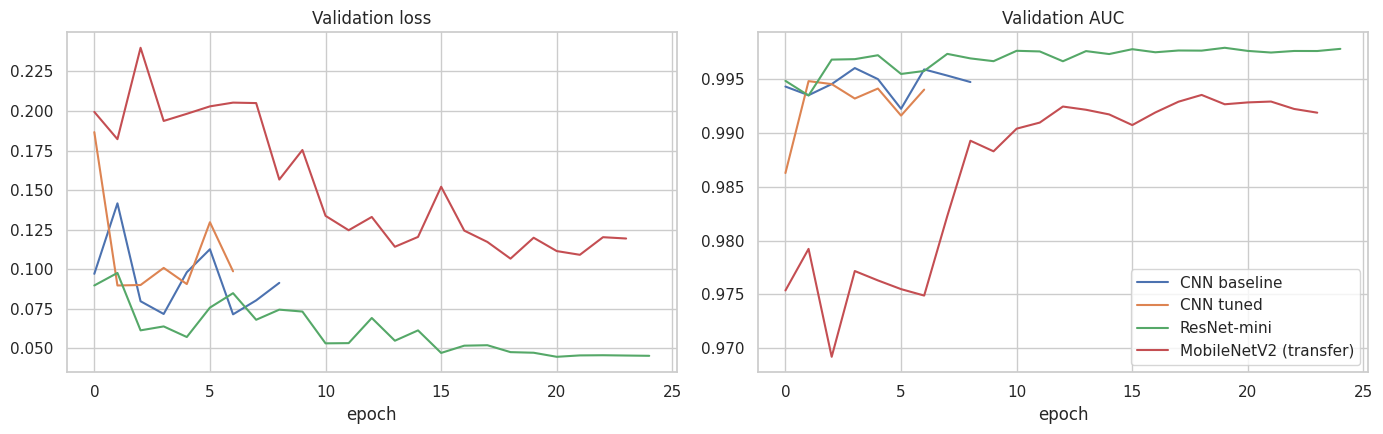

,final train AUC,final val AUC,gap
CNN baseline,0.9988,0.9947,0.0041
CNN tuned,0.9975,0.9940,0.0035
ResNet-mini,0.9995,0.9978,0.0017
MobileNetV2 (transfer),0.9990,0.9919,0.0071


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for n, h in HIST.items():
    ax[0].plot(h.val_loss.values, label=n); ax[1].plot(h.val_auc.values, label=n)
ax[0].set(title='Validation loss', xlabel='epoch'); ax[1].set(title='Validation AUC', xlabel='epoch'); ax[1].legend()
plt.tight_layout(); savefig('p2_02_training_curves.png'); plt.show()

gap = pd.DataFrame({n: {'final train AUC': h.auc.iloc[-1], 'final val AUC': h.val_auc.iloc[-1], 'gap': h.auc.iloc[-1] - h.val_auc.iloc[-1]} for n, h in HIST.items()}).T.round(4)
gap

**What it tells us:** a large train-vs-validation AUC gap means overfitting to the training people. Note that the training AUC is measured *with augmentation on*, so it is slightly pessimistic.

## 5. Model comparison
All numbers below are computed on the **untouched test set** (different people from the training set), with the threshold chosen on validation data.

In [33]:
res = pd.DataFrame(results)
cols = ['model', 'family', 'accuracy', 'precision_closed', 'recall_closed', 'f1_closed', 'auc', 'val_f1', 'threshold', 'train_time_s', 'ms_per_image']
comp = res[cols].sort_values('val_f1', ascending=False).reset_index(drop=True)
res.to_csv(f'{PROC_DIR}/phase2_model_comparison.csv', index=False)
comp.round(4)

,model,family,accuracy,precision_closed,recall_closed,f1_closed,auc,val_f1,threshold,train_time_s,ms_per_image
0,ResNet-mini,Deep learning,0.9733,0.9885,0.9609,0.9745,0.9966,0.9868,0.70,1957.9088,1.2854
1,CNN baseline,Deep learning,0.9731,0.9854,0.9637,0.9744,0.9968,0.9771,0.66,225.4118,0.5034
2,CNN tuned,Deep learning,0.9566,0.9452,0.9749,0.9598,0.9949,0.9703,0.60,112.5151,0.3915
3,MobileNetV2 (transfer),Deep learning,0.9459,0.9396,0.9600,0.9496,0.9882,0.9586,0.20,886.2069,0.9302
4,SVM-RBF (HOG),Classical ML,0.9153,0.9379,0.9001,0.9186,0.9729,0.9176,0.53,20.3333,1.4406
5,RandomForest (HOG),Classical ML,0.9034,0.9043,0.9150,0.9096,0.9689,0.9091,0.50,117.6812,0.9311
6,LogReg (HOG),Classical ML,0.8976,0.9282,0.8749,0.9008,0.9589,0.8917,0.66,3.8240,0.9095


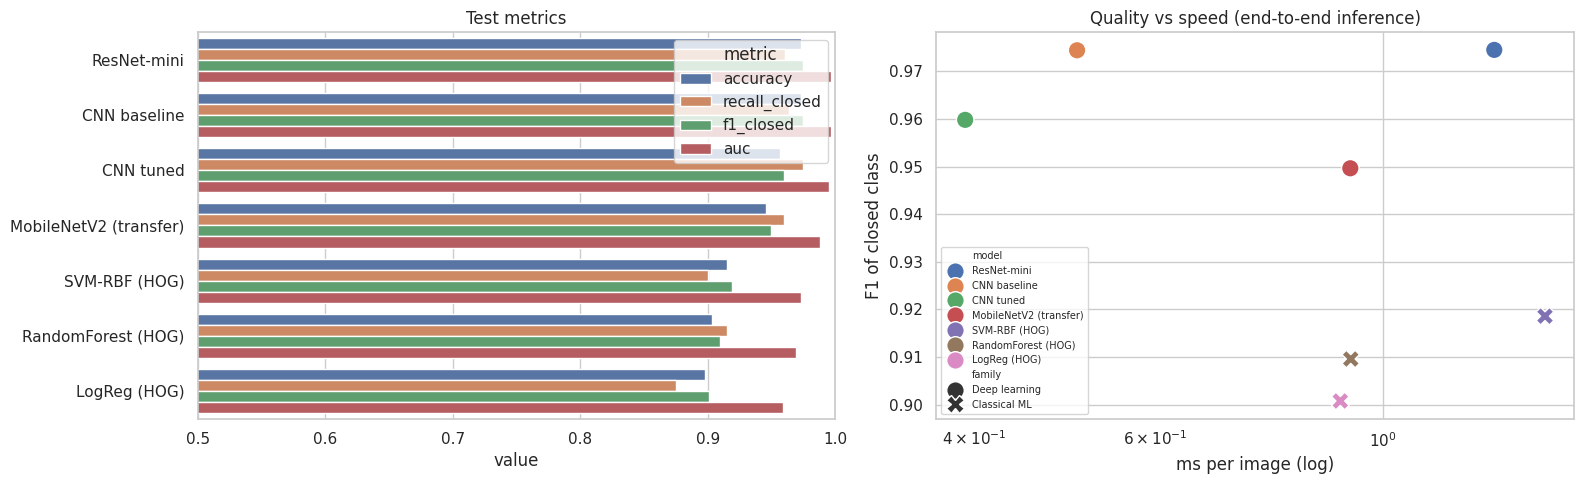

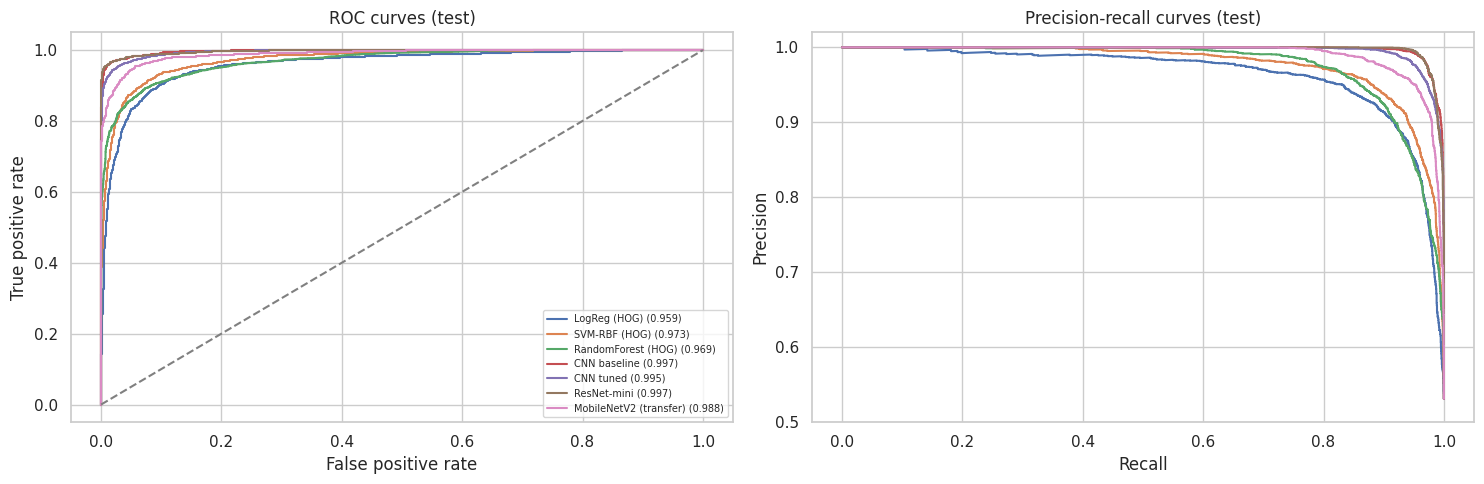

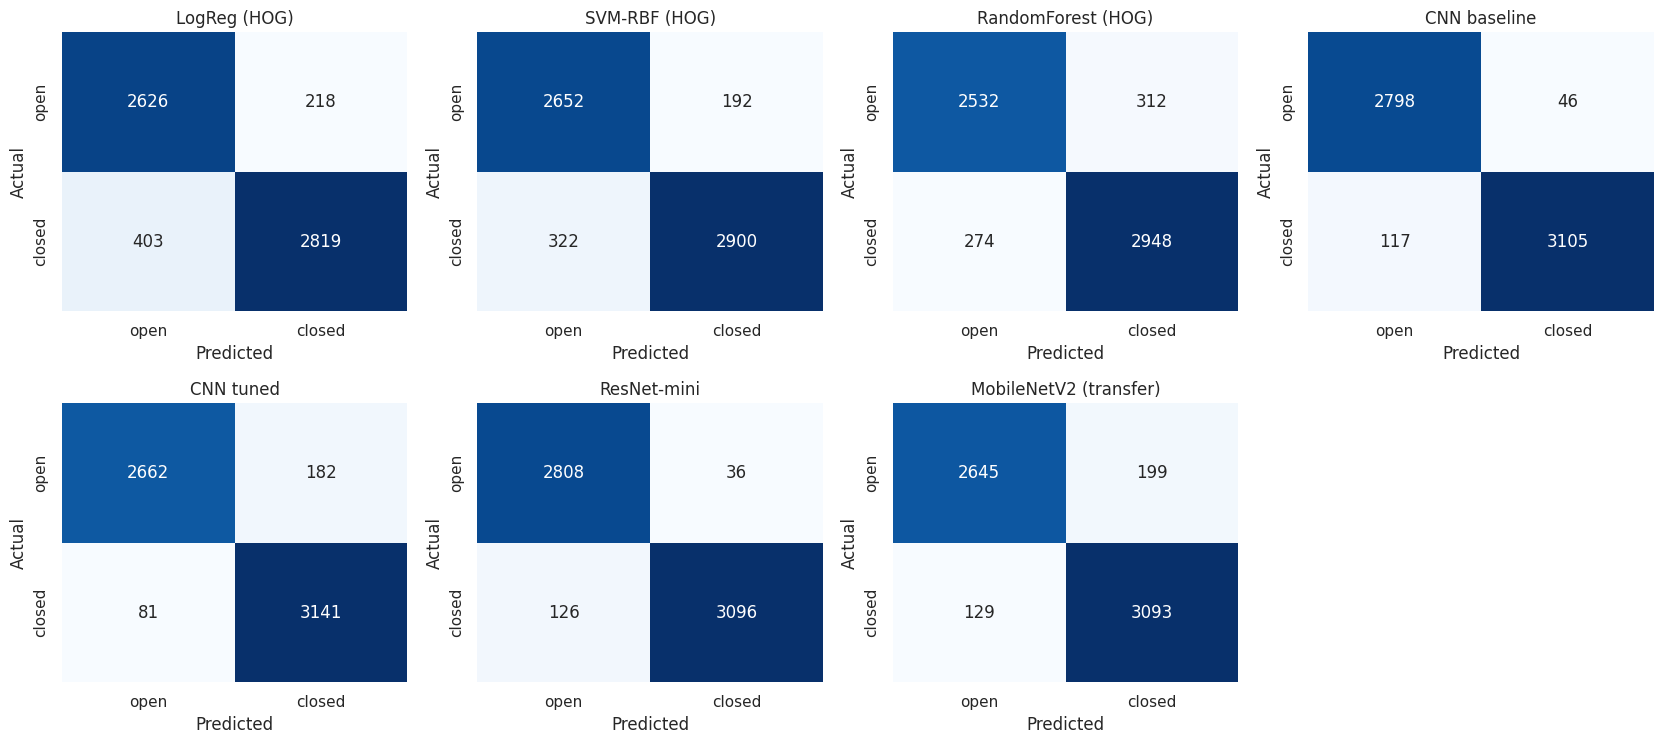

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
mm = comp.melt(id_vars='model', value_vars=['accuracy', 'recall_closed', 'f1_closed', 'auc'], var_name='metric')
sns.barplot(data=mm, y='model', x='value', hue='metric', ax=ax[0], order=comp.model); ax[0].set_xlim(0.5, 1.0); ax[0].set_title('Test metrics'); ax[0].set_ylabel('')
sns.scatterplot(data=comp, x='ms_per_image', y='f1_closed', hue='model', style='family', s=160, ax=ax[1]); ax[1].set_xscale('log')
ax[1].set(title='Quality vs speed (end-to-end inference)', xlabel='ms per image (log)', ylabel='F1 of closed class'); ax[1].legend(fontsize=7)
plt.tight_layout(); savefig('p2_03_model_comparison.png'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for n, p in PRED.items():
    fpr, tpr, _ = roc_curve(yte, p['test']); ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(yte, p['test']):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p['test']); ax[1].plot(rc, pr, label=n)
ax[0].plot([0, 1], [0, 1], '--', color='gray'); ax[0].set(title='ROC curves (test)', xlabel='False positive rate', ylabel='True positive rate'); ax[0].legend(fontsize=7)
ax[1].set(title='Precision-recall curves (test)', xlabel='Recall', ylabel='Precision', ylim=(0.5, 1.02))
plt.tight_layout(); savefig('p2_04_roc_pr.png'); plt.show()

n = len(PRED); cols_ = 4; rows_ = int(np.ceil(n / cols_))
fig, ax = plt.subplots(rows_, cols_, figsize=(4.2 * cols_, 3.8 * rows_)); ax = np.array(ax).ravel()
for a, (nme, p) in zip(ax, PRED.items()):
    cm = confusion_matrix(yte, (p['test'] >= p['thr']).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a, xticklabels=['open', 'closed'], yticklabels=['open', 'closed'])
    a.set(title=nme, xlabel='Predicted', ylabel='Actual')
for a in ax[n:]: a.axis('off')
plt.tight_layout(); savefig('p2_05_confusion_matrices.png'); plt.show()

## 6. Analysis of the best model
The best model is chosen by **validation F1** (never by test score). We then look at *where* it works and where it fails.

Best overall (by validation F1): ResNet-mini | best deep model: ResNet-mini
  condition         group    n  accuracy  recall_closed  specificity_open
   lighting     bad light 3595     0.972          0.959             0.988
   lighting    good light 2471     0.975          0.965             0.986
    glasses    no glasses 5737     0.976          0.967             0.988
    glasses       glasses  329     0.918          0.657             0.985
reflections no reflection 5791     0.976          0.966             0.988
reflections         small   66     0.970          0.667             1.000
reflections           big  209     0.900          0.575             0.976
     sensor      sensor 1 6066     0.973          0.961             0.987
     gender          male 4418     0.964          0.935             0.986
     gender        female 1648     0.999          0.998             1.000


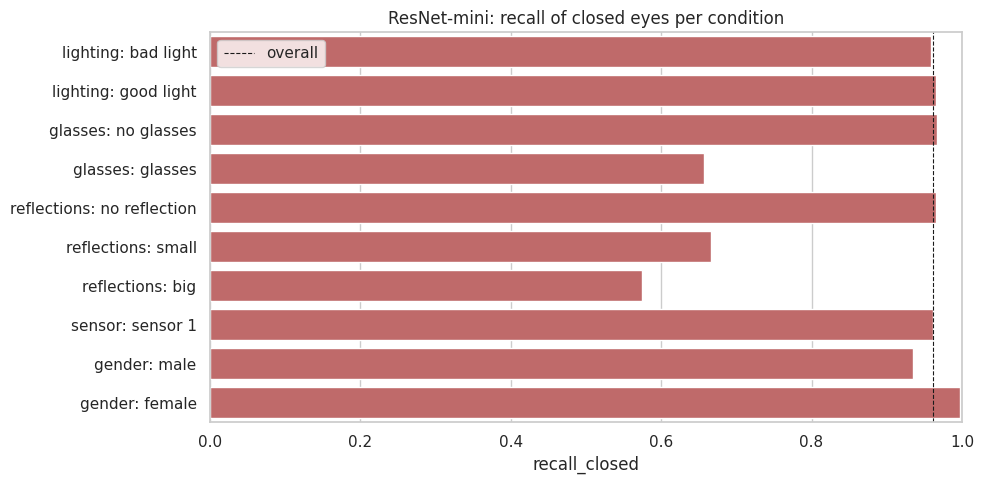


Per-subject accuracy: min 0.935 | median 0.977 | max 0.999
Weakest subjects:
         accuracy     n
subject                
s0030       0.935  1384
s0027       0.958   665
s0009       0.974   387
s0005       0.980   736
s0026       0.986  1246


In [35]:
best_name = comp.iloc[0].model
best_deep = comp[comp.family == 'Deep learning'].iloc[0].model
print('Best overall (by validation F1):', best_name, '| best deep model:', best_deep)
P = PRED[best_name]; thr = P['thr']; yhat = (P['test'] >= thr).astype(int)

tm = te_meta.copy(); tm['pred'] = yhat; tm['correct'] = (yhat == yte); tm['prob'] = P['test']
rows = []
for col, names in [('lighting', {0: 'bad light', 1: 'good light'}), ('glasses', {0: 'no glasses', 1: 'glasses'}),
                   ('reflections', {0: 'no reflection', 1: 'small', 2: 'big'}), ('sensor', {1: 'sensor 1', 2: 'sensor 2', 3: 'sensor 3'}),
                   ('gender', {0: 'male', 1: 'female'})]:
    for v, g in tm.groupby(col):
        cl = g[g.closed == 1]
        rows.append({'condition': col, 'group': names.get(v, v), 'n': len(g), 'accuracy': g.correct.mean(),
                     'recall_closed': (cl.pred == 1).mean() if len(cl) else np.nan,
                     'specificity_open': (g[g.closed == 0].pred == 0).mean() if (g.closed == 0).any() else np.nan})
by_cond = pd.DataFrame(rows).round(3); by_cond.to_csv(f'{PROC_DIR}/phase2_best_by_condition.csv', index=False)
print(by_cond.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=by_cond.assign(label=by_cond.condition + ': ' + by_cond.group.astype(str)), y='label', x='recall_closed', color='indianred', ax=ax)
ax.axvline(recall_score(yte, yhat), color='k', ls='--', lw=.8, label='overall'); ax.legend(); ax.set_xlim(0, 1)
ax.set_title(f'{best_name}: recall of closed eyes per condition'); ax.set_ylabel('')
plt.tight_layout(); savefig('p2_06_recall_by_condition.png'); plt.show()

ps = tm.groupby('subject').correct.agg(['mean', 'size']).rename(columns={'mean': 'accuracy', 'size': 'n'}).sort_values('accuracy')
print(f"\nPer-subject accuracy: min {ps.accuracy.min():.3f} | median {ps.accuracy.median():.3f} | max {ps.accuracy.max():.3f}")
print('Weakest subjects:'); print(ps.head(5).round(3).to_string())

**Reading the table:** groups with a recall clearly below the dashed *overall* line are the model's weak spots. Check the `n` column - small groups are noisy.

### 6.1 Threshold trade-off (validation set)

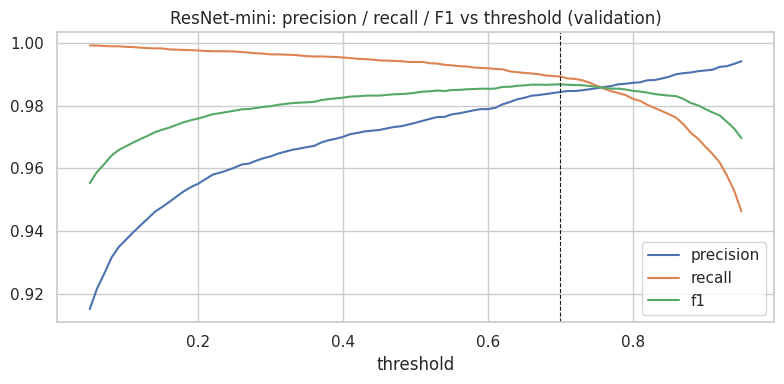

For a drowsiness alarm you can trade precision for recall by lowering the threshold:
  recall >= 0.95: threshold 0.94 -> precision 0.993
  recall >= 0.98: threshold 0.82 -> precision 0.988


In [36]:
ts = np.arange(0.05, 0.96, 0.01); pv = PRED[best_name]['val']
tab = pd.DataFrame({'threshold': ts, 'precision': [precision_score(yva, (pv >= t).astype(int), zero_division=0) for t in ts],
                    'recall': [recall_score(yva, (pv >= t).astype(int), zero_division=0) for t in ts],
                    'f1': [f1_score(yva, (pv >= t).astype(int), zero_division=0) for t in ts]})
ax = tab.set_index('threshold').plot(figsize=(8, 4), title=f'{best_name}: precision / recall / F1 vs threshold (validation)')
ax.axvline(thr, color='k', ls='--', lw=.8); plt.tight_layout(); savefig('p2_07_threshold_tradeoff.png'); plt.show()
print('For a drowsiness alarm you can trade precision for recall by lowering the threshold:')
for target in (0.95, 0.98):
    ok = tab[tab.recall >= target]
    if len(ok): r = ok.iloc[-1]; print(f'  recall >= {target:.2f}: threshold {r.threshold:.2f} -> precision {r.precision:.3f}')

### 6.2 Error analysis - the most confident mistakes

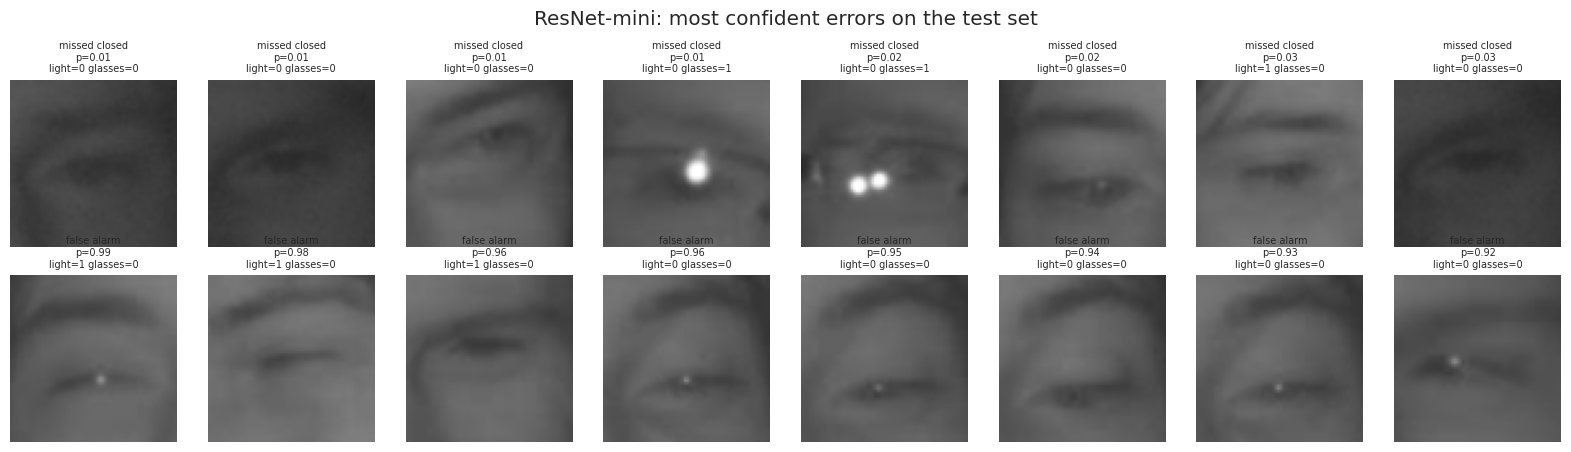

Errors by condition  (share of all errors vs share of test set):
lighting -> {0: '0.62 vs 0.59', 1: '0.38 vs 0.41'}
glasses -> {0: '0.83 vs 0.95', 1: '0.17 vs 0.05'}
reflections -> {0: '0.86 vs 0.95', 2: '0.13 vs 0.03', 1: '0.01 vs 0.01'}
sensor -> {1: '1.00 vs 1.00'}


In [37]:
Xs = Xte[..., 0]
fn = np.where((yte == 1) & (yhat == 0))[0]; fp = np.where((yte == 0) & (yhat == 1))[0]
fn = fn[np.argsort(P['test'][fn])][:8]; fp = fp[np.argsort(-P['test'][fp])][:8]      # most confident errors first
fig, ax = plt.subplots(2, 8, figsize=(16, 4.6))
for r, (idx, ttl) in enumerate([(fn, 'missed closed'), (fp, 'false alarm')]):
    for j in range(8):
        ax[r, j].axis('off')
        if j < len(idx):
            k = idx[j]; ax[r, j].imshow(Xs[k], cmap='gray', vmin=0, vmax=1)
            ax[r, j].set_title(f"{ttl}\np={P['test'][k]:.2f}\nlight={tm.lighting[k]} glasses={tm.glasses[k]}", fontsize=7)
plt.suptitle(f'{best_name}: most confident errors on the test set'); plt.tight_layout(); savefig('p2_08_error_gallery.png'); plt.show()
print('Errors by condition  (share of all errors vs share of test set):')
for col in ['lighting', 'glasses', 'reflections', 'sensor']:
    err = tm[~tm.correct][col].value_counts(normalize=True); allv = tm[col].value_counts(normalize=True)
    print(col, '->', {int(k): f'{err.get(k, 0):.2f} vs {allv[k]:.2f}' for k in allv.index})

### 6.3 What does the CNN look at? (occlusion sensitivity - feature importance for images)
We slide a grey patch over the eye and measure how much the predicted probability changes. Bright areas = regions the model relies on. For a sensible model these should be the **eyelid / iris region**, not the background.

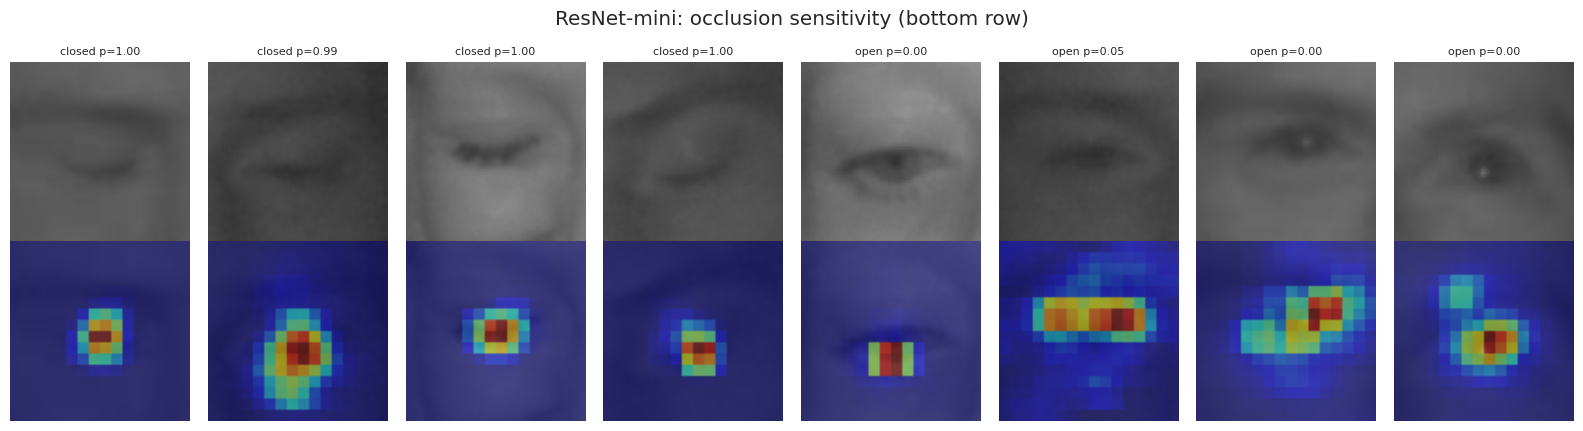

In [38]:
dm = MODELS[best_deep]; pd_test = PRED[best_deep]['test']; thr_d = PRED[best_deep]['thr']
def occlusion_map(model, img, patch=12, stride=4):
    p0 = model.predict(img[None], verbose=0)[0, 0]; pos = list(range(0, 64 - patch + 1, stride))
    batch = []
    for y in pos:
        for x in pos:
            im = img.copy(); im[y:y + patch, x:x + patch] = 0.5; batch.append(im)
    pr = model.predict(np.array(batch), batch_size=256, verbose=0).ravel(); heat = np.zeros((64, 64)); cnt = np.zeros((64, 64)); i = 0
    for y in pos:
        for x in pos:
            heat[y:y + patch, x:x + patch] += abs(p0 - pr[i]); cnt[y:y + patch, x:x + patch] += 1; i += 1
    return p0, heat / np.maximum(cnt, 1)

ok_closed = np.where((yte == 1) & (pd_test >= thr_d))[0]; ok_open = np.where((yte == 0) & (pd_test < thr_d))[0]
pick = list(rng.choice(ok_closed, 4, replace=False)) + list(rng.choice(ok_open, 4, replace=False))
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for j, k in enumerate(pick):
    p0, hm = occlusion_map(dm, Xte[k])
    ax[0, j].imshow(Xte[k, ..., 0], cmap='gray', vmin=0, vmax=1); ax[0, j].set_title(f"{'closed' if yte[k] else 'open'} p={p0:.2f}", fontsize=8)
    ax[1, j].imshow(Xte[k, ..., 0], cmap='gray', vmin=0, vmax=1); ax[1, j].imshow(hm, cmap='jet', alpha=0.5)
    ax[0, j].axis('off'); ax[1, j].axis('off')
plt.suptitle(f'{best_deep}: occlusion sensitivity (bottom row)'); plt.tight_layout(); savefig('p2_09_occlusion.png'); plt.show()

## 7. Save the best model for the website
The web app needs one Keras model, the decision threshold and the exact preprocessing. We save the **best deep model** (and the best classical model for reference).

In [40]:
import json
import pandas as pd
import joblib

MODELS[best_deep].save(f'{MODEL_DIR}/best_model.keras')

metrics = comp[comp.model == best_deep].iloc[0][
    ['accuracy', 'precision_closed', 'recall_closed', 'f1_closed', 'auc']
]

metrics = pd.to_numeric(metrics, errors='coerce')

config = {
    'model_name': best_deep,
    'threshold': float(PRED[best_deep]['thr']),
    'input_size': [64, 64],
    'channels': 1,
    'preprocessing': 'grayscale, resize to 64x64, divide by 255',
    'positive_class': 'closed (1)',
    'test_metrics': metrics.round(4).to_dict()
}

json.dump(config, open(f'{MODEL_DIR}/phase2_config.json', 'w'), indent=2)

best_classical = comp[comp.family == 'Classical ML'].iloc[0].model

joblib.dump(
    MODELS[best_classical],
    f'{MODEL_DIR}/phase2_baseline_{best_classical.lower()}.joblib'
)

print(json.dumps(config, indent=2))

{
  "model_name": "ResNet-mini",
  "threshold": 0.7000000000000002,
  "input_size": [
    64,
    64
  ],
  "channels": 1,
  "preprocessing": "grayscale, resize to 64x64, divide by 255",
  "positive_class": "closed (1)",
  "test_metrics": {
    "accuracy": 0.9733,
    "precision_closed": 0.9885,
    "recall_closed": 0.9609,
    "f1_closed": 0.9745,
    "auc": 0.9966
  }
}


## 8. Conclusion

In [41]:
b = comp.iloc[0]; base_row = comp[comp.model == 'CNN baseline'].iloc[0]; cl = comp[comp.family == 'Classical ML'].iloc[0]
weak = by_cond.dropna(subset=['recall_closed']).query('n >= 100').sort_values('recall_closed').head(3)
print(f"* Best model by validation F1: {b.model} -> test F1(closed) {b.f1_closed:.3f}, recall {b.recall_closed:.3f}, precision {b.precision_closed:.3f}, AUC {b.auc:.3f}.")
print(f"* Improvement over the Phase 1 CNN baseline: F1 {b.f1_closed - base_row.f1_closed:+.3f}, AUC {b.auc - base_row.auc:+.3f}.")
print(f"* Best classical model ({cl.model}): F1 {cl.f1_closed:.3f} vs best deep model {comp[comp.family=='Deep learning'].iloc[0].f1_closed:.3f} - "
      f"deep learning learns the eye features directly from pixels instead of relying on hand-made HOG descriptors.")
print('* Weakest conditions for the best model (recall of closed eyes, n>=100):')
print(weak[['condition', 'group', 'n', 'recall_closed']].to_string(index=False))
print(f"* Speed: {b.ms_per_image:.2f} ms per image end-to-end, fast enough for real-time use on a webcam stream.")

* Best model by validation F1: ResNet-mini -> test F1(closed) 0.975, recall 0.961, precision 0.989, AUC 0.997.
* Improvement over the Phase 1 CNN baseline: F1 +0.000, AUC -0.000.
* Best classical model (SVM-RBF (HOG)): F1 0.919 vs best deep model 0.975 - deep learning learns the eye features directly from pixels instead of relying on hand-made HOG descriptors.
* Weakest conditions for the best model (recall of closed eyes, n>=100):
  condition   group    n  recall_closed
reflections     big  209          0.575
    glasses glasses  329          0.657
     gender    male 4418          0.935
* Speed: 1.29 ms per image end-to-end, fast enough for real-time use on a webcam stream.


### Limitations and what could be improved
* **Single-frame decision:** one image says "closed", but drowsiness is about *how long* the eyes stay closed (PERCLOS / blink duration). The web app should smooth predictions over several frames.
* **Weak conditions:** the per-condition table and the error gallery show where recall drops (typically bad lighting, glasses, reflections). More data or targeted augmentation (synthetic reflections, stronger low-light) for those groups is the most promising improvement.
* **Domain shift:** test people come from the same dataset and sensors as training. A webcam in a car or at home may look different; a short evaluation on self-recorded images is recommended before real use.
* **Resolution:** images are 64x64; MobileNetV2 is upsampled to 96x96 and cannot recover missing detail.
* **Classical models** were tuned and fitted on subsamples for speed; with more compute they would improve a little, but are unlikely to reach the CNNs.
* **Next steps:** ensembling the best models, test-time augmentation, probability calibration, and temporal models (CNN + LSTM / majority vote over frames).